# `sciml` tutorial

This notebook presents a complete example of how to use the `sciml` package to solve, with a PINN, the one-dimensional steady-state advection–diffusion problem parametrized by the Peclet number.

**Problem definition:**

$$
    \begin{cases}
        u_{xx} - \text{Pe} \, u_x = 0,
        & (x, \text{Pe}) \in [0, 1] \times [0, 10], \\
        u(0, \text{Pe}) = 1,
        & \text{Pe} \in [0, 10], \\
        u(1, \text{Pe}) = 0,
        & \text{Pe} \in [0, 10].
    \end{cases}
$$

**Analytical solution:**

$$
    u(x, \text{Pe}) = \frac{1 - \exp(\text{Pe}(x - 1))}{1 - \exp(-\text{Pe})}.
$$

### 1. Import packages
---

In [1]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='torch.cuda')

import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from collections.abc import Generator
from contextlib import contextmanager

from sciml.interfaces import ModelBase
from sciml.contracts import Context
from sciml.core import Objective, Progress, Strategy, Trainer, Progress, Checkpoint
from sciml.implementations.networks import MLP
from sciml.implementations.losses import Residual, Supervised
from sciml.implementations.samplers import LatinHypercube
from sciml.implementations.metrics import MaxError, RelativeLpNorm
from sciml.utils import plot_history

### 2. Parameters definition
---

In [2]:
# torch device and dtype
device = "cpu"
dtype = torch.float32

# Problem domain
peclet_min = 0.0
peclet_max = 10.0

# Neural network
input_dim = 2               # (x, Pe)
output_dim = 1              # u
hidden_layers = (32, 32)

# Samples
num_residual = 2000
num_boundary = 500
num_validation = 5000

# Training
num_iterations = 5000
learning_rate = 1e-3
seed = 1

# Results
results_path = Path("./results/t0/")
checkpoint_path = results_path / "checkpoints"
checkpoint_interval = 1000
progress_interval = 100
validation_interval = 500

# Reproducibility
torch.manual_seed(seed)

### 3. Analytical solution
---

Functino definition

In [3]:
def solution(x: np.ndarray, peclet: np.ndarray) -> np.ndarray:
    eps = 1e-3
    peclet = np.clip(peclet, eps, None)
    return (1 - np.exp(peclet * (x - 1))) / (1 - np.exp(-peclet))

Field visualization

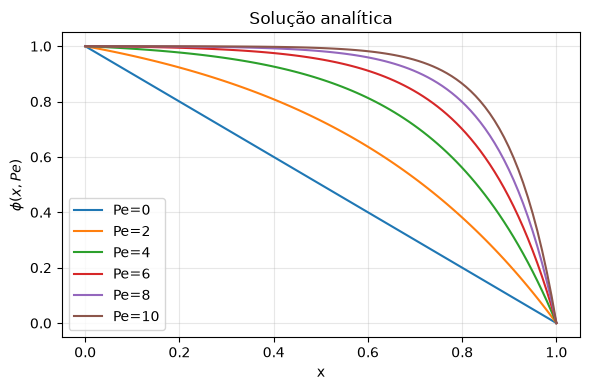

In [4]:
x_plot = np.linspace(0, 1, 100).reshape(-1, 1)

plt.figure(figsize=(6, 4))
for pe_val in np.arange(peclet_min, peclet_max + 1, 2):
    pe_plot = np.full_like(x_plot, pe_val)
    plt.plot(x_plot, solution(x_plot, pe_plot), label=f"Pe={pe_val:.0f}")

plt.xlabel("x")
plt.ylabel(r"$\phi(x, Pe)$")
plt.title("Solução analítica")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Components
---

#### 4.1. Model

In [5]:
# Model implementation
class Model(ModelBase):
    def __init__(self):
        self.network = MLP(input_dim, output_dim, hidden_layers).to(device, dtype)
        return
    
    def compute(self, context) -> None:
        context.requires_grad("x")
        inputs = torch.cat([context["x"], context["peclet"]], dim=1)
        context["phi"] = self.network(inputs)
        return

    @contextmanager
    def evaluation_mode(self) -> Generator[None, None, None]:
        modes = {m: m.training for m in self.network.modules()}
        try:
            self.network.eval()
            yield
        finally:
            for module, training in modes.items():
                module.training = training
        return

# Model difinition
model = Model()

### 4.2. Losses

In [6]:
# Residual function
def residual(context: Context) -> torch.Tensor:
    phi_x, key = context.partial("phi", "x")
    phi_xx, _ = context.partial(key, "x")
    peclet = context["peclet"]
    return phi_xx - peclet * phi_x

# Losses definition
residual_loss = Residual(
    name="loss",
    weight=1.0,
    residual=residual,
)

left_bc_loss = Supervised(
    name="loss",
    weight=10.0,
    input_keys=["phi"],
    target_keys=["target"],
)

right_bc_loss = Supervised(
    name="loss",
    weight=10.0,
    input_keys=["phi"],
    target_keys=["target"],
)

# Validation
max_error_val = Supervised(
    name="max_error",
    input_keys=["phi"],
    target_keys=["target"],
    reduction=MaxError(),
)

rl2_val = Supervised(
    name="rl2",
    input_keys=["phi"],
    target_keys=["target"],
    reduction=RelativeLpNorm(),
)

### 4.3. Samplers

In [7]:
# Interior points
residual_sampler = LatinHypercube(
    dim=2,
    num_points=num_residual,
    batch_size=num_residual,
    input_keys=["x", "peclet"],
    bounds=[(1, (peclet_min, peclet_max))],
    seed=seed,
    device=device,
    dtype=dtype,
)

# Boundary points
left_bc_sampler = LatinHypercube(
    dim=2,
    num_points=num_boundary,
    batch_size=num_boundary,
    input_keys=["x", "peclet"],
    target_keys=["target"],
    target_fn=solution,
    bounds=[(1, (peclet_min, peclet_max))],
    insertions=[(0, 0.0)],
    seed=seed,
    device=device,
    dtype=dtype,
)

right_bc_sampler = LatinHypercube(
    dim=2,
    num_points=num_boundary,
    batch_size=num_boundary,
    input_keys=["x", "peclet"],
    target_keys=["target"],
    target_fn=solution,
    bounds=[(1, (peclet_min, peclet_max))],
    insertions=[(0, 1.0)],
    seed=seed,
    device=device,
    dtype=dtype,
)

# Validation
val_interp_sampler = LatinHypercube(
    dim=2,
    num_points=num_validation,
    batch_size=num_validation,
    input_keys=["x", "peclet"],
    target_keys=["target"],
    target_fn=solution,
    bounds=[(1, (peclet_min, peclet_max))],
    seed=seed,
    device=device,
    dtype=dtype,
)

val_extrap_sampler = LatinHypercube(
    dim=2,
    num_points=num_validation,
    batch_size=num_validation,
    input_keys=["x", "peclet"],
    target_keys=["target"],
    target_fn=solution,
    bounds=[(1, (peclet_max, 1.5 * peclet_max))],
    seed=seed,
    device=device,
    dtype=dtype,
)

### 4.4. Optimization strategy

In [8]:
# Residual and boundary objectives
objectives = [
    Objective("residual", residual_sampler, [residual_loss]),
    Objective("left_bc", left_bc_sampler, [left_bc_loss]),
    Objective("right_bc", right_bc_sampler, [right_bc_loss]),
]

# Strategy based only on Adam optimizer
strategies = [
    Strategy("adam", torch.optim.Adam(model.network.parameters(), lr=learning_rate)),
]

# Progress and checkpoint
checkpoint = Checkpoint(
    path=checkpoint_path,
    model=model.network,
    strategies=strategies,
    prefix="checkpoint_it",
)

progress = Progress(
    strategies=strategies,
    verbose=True,
    interval=progress_interval,
    path=results_path,
    filename="history.csv",
)

# Validation
validation = [
    Objective("interp", val_interp_sampler, [max_error_val, rl2_val]),
    Objective("extrap", val_extrap_sampler, [max_error_val, rl2_val]),
]

# Trainer definition
trainer = Trainer(
    model=model,
    objectives=objectives,
    strategies=strategies,
    progress=progress,
    checkpoint=checkpoint,
    checkpoint_interval=checkpoint_interval,
    validation=validation,
    validation_interval=validation_interval,
)

## 5. Optimization
---

In [9]:
trainer.fit(num_iterations=num_iterations)

Iteration 5000 - 234.6 it/s
- adam: func = 7.079e-04; ratio = 1.322e-04 [active]


## 6. Post-processing
---

Visualize training history

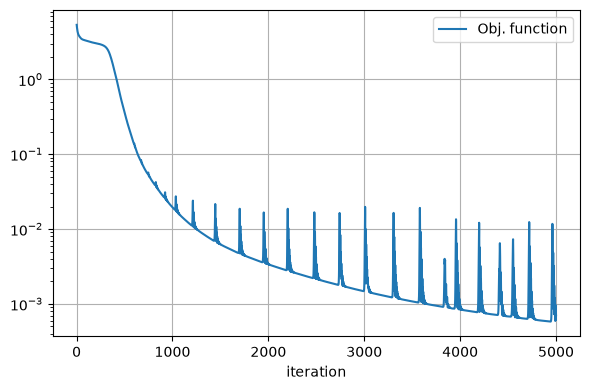

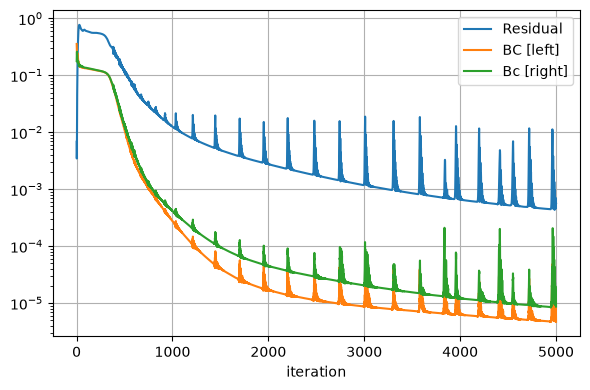

In [10]:
plot_history(
    csv=results_path / "adam_history.csv",
    y_keys=["objective"],
    legend=["Obj. function"],
)

plot_history(
    csv=results_path / "adam_history.csv",
    y_keys=["residual.loss", "left_bc.loss", "right_bc.loss"],
    legend=["Residual", "BC [left]", "Bc [right]"],
)

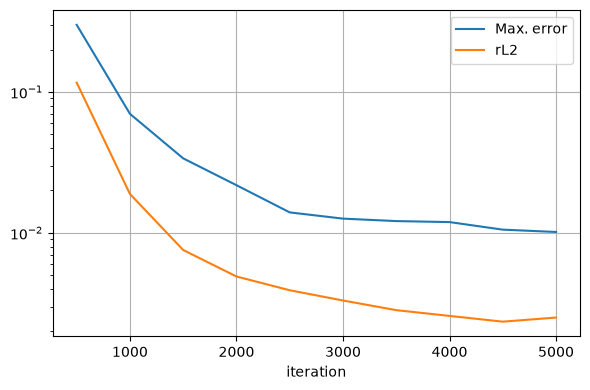

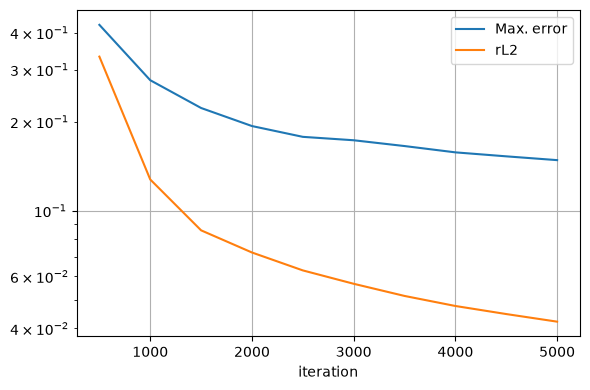

In [11]:
plot_history(
    csv=results_path / "validation_history.csv",
    y_keys=["interp.max_error", "interp.rl2"],
    legend=["Max. error", "rL2"],
)

plot_history(
    csv=results_path / "validation_history.csv",
    y_keys=["extrap.max_error", "extrap.rl2"],
    legend=["Max. error", "rL2"],
)

Visualize predicted field

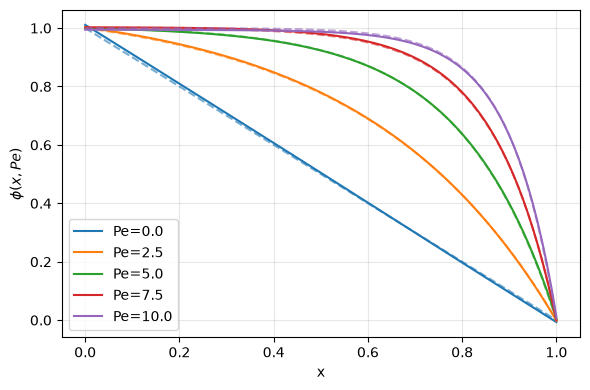

In [12]:
model.network.eval()

plt.figure(figsize=(6, 4))

with model.evaluation_mode():
    
    x_plot = np.linspace(0, 1, 100).reshape(-1, 1)
    peclet_values = [0, 2.5, 5, 7.5, 10]

    for pe_val in peclet_values:
        pe_plot = np.full_like(x_plot, pe_val)

        u_ref = solution(x_plot, pe_plot)

        inputs = torch.as_tensor(np.concatenate([x_plot, pe_plot], axis=1), dtype=dtype)
        u_pred = model.network(inputs).detach().numpy()

        line, = plt.plot(x_plot, u_pred, label=f"Pe={pe_val:.1f}")
        plt.plot(x_plot, u_ref, "--", color=line.get_color(), alpha=0.6)

plt.xlabel("x")
plt.ylabel(r"$\phi(x, Pe)$")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Error for different peclet numbers

In [13]:
# Erro relativo (norma L2) para cada Pe, usando a mesma métrica do pacote
max_error = MaxError()
rl2 = RelativeLpNorm()

with model.evaluation_mode():

    for pe_val in peclet_values:
        pe_plot = np.full_like(x_plot, pe_val)
        phi_ref = solution(x_plot, pe_plot)

        inputs = torch.as_tensor(np.concatenate([x_plot, pe_plot], axis=1), dtype=dtype)
        phi_pred = model.network(inputs).detach().numpy()

        error_1 = max_error.evaluate(torch.as_tensor(phi_pred), torch.as_tensor(phi_ref))
        error_2 = rl2.evaluate(torch.as_tensor(phi_pred), torch.as_tensor(phi_ref))

        print(f"Pe={pe_val:4.1f}   max_error = {error_1.item():.4e}; rl2 = {error_2.item():.4e}")

Pe= 0.0   max_error = 1.1031e-02; rl2 = 1.1686e-02
Pe= 2.5   max_error = 2.7771e-03; rl2 = 2.7327e-03
Pe= 5.0   max_error = 5.3681e-03; rl2 = 2.0177e-03
Pe= 7.5   max_error = 3.1365e-03; rl2 = 3.0485e-03
Pe=10.0   max_error = 1.2175e-02; rl2 = 6.1035e-03
